<a href="https://colab.research.google.com/github/G-Yadidhya/notebook/blob/main/02_your_first_readable_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 — The model is just a rule you can read

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/G-Yadidhya/notebook/blob/main/notebooks/02_your_first_readable_model.ipynb?flush_cache=true)

You'll:
1. Write a **1-line hand rule** and rank pages with it.
2. Fit a **depth-2 decision tree** and `print` it — the model "learned" a readable if/else. Then compare — where does it beat your rule, and where doesn’t it?
3. See **why you never feed the outcome back in** — that's leakage.

The payoff isn't a high score. It's: *my intuition was rough, the model found the real signal, and I can read exactly what it found.*

## 0. Setup (Colab or local)

In [ ]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

# The label: a page is 'declining' when its recent trend is down. Simple, honest starter label.
df["is_declining_label"] = df["trend_direction"].str.lower().eq("down").astype(int)
print(df.shape[0], "pages |  declining rate:", round(df["is_declining_label"].mean(), 3))

30000 pages |  declining rate: 0.542


## 1. A rule you write by hand: `stale x visible`
Intuition: a page worth reviewing is one that is **stale** (not updated in a while) **and** still **visible** (getting impressions). Rank those by how much exposure they have.

In [ ]:
stale   = (df["days_since_last_update"] >= 180).astype(int)
visible = (df["impressions_90d"] >= 500).astype(int)
df["hand_rule_score"] = stale * visible * df["impressions_90d"]

top10 = df.sort_values("hand_rule_score", ascending=False).head(10)
top10[["impressions_90d", "days_since_last_update", "avg_position", "ctr", "trend_direction"]]

,impressions_90d,days_since_last_update,avg_position,ctr,trend_direction
16751,61678,194,19.7,0.15,down
16514,59472,194,24.8,0.13,down
7021,25715,194,22.2,0.23,down
21268,13299,193,10.5,0.49,down
11489,7812,194,39.0,0.01,down
12045,7558,193,17.9,0.20,down
698,4590,194,31.0,0.00,down
5327,4556,194,16.4,0.33,down
26810,4429,194,25.3,0.38,down
20837,1697,193,15.8,0.12,down


We need a way to score any ranking. **Precision@K** = of the top K pages a ranking flags, what fraction are actually declining.

In [ ]:
def precision_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores))
    topk = np.asarray(labels)[order[:k]]
    return topk.mean()

y = df["is_declining_label"].values
for k in (20, 50):
    print(f"Hand rule  Precision@{k}: {precision_at_k(df['hand_rule_score'], y, k):.3f}")

Hand rule  Precision@20: 0.900
Hand rule  Precision@50: 0.680


## 2. Let a model learn the rule — then read it
A **depth-2 decision tree** can only ask 3 yes/no questions. That constraint is the point: whatever it learns, you can read.

We give it a few **pre-decision** signals — never product flags.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text

features = ["content_age_days", "days_since_last_update", "impressions_90d",
            "avg_position", "ctr", "word_count"]
X = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)

tree = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42)
tree.fit(X, y)

print(export_text(tree, feature_names=features))

|--- impressions_90d <= 5.50
|   |--- avg_position <= 0.75
|   |   |--- class: 0
|   |--- avg_position >  0.75
|   |   |--- class: 0
|--- impressions_90d >  5.50
|   |--- content_age_days <= 312.50
|   |   |--- class: 1
|   |--- content_age_days >  312.50
|   |   |--- class: 0



That printout **is** the model — a human-readable if/else. Now rank pages by the tree's probability and score it the same way.

In [ ]:
tree_score = tree.predict_proba(X)[:, 1]
for k in (20, 50):
    hr = precision_at_k(df["hand_rule_score"], y, k)
    tr = precision_at_k(tree_score, y, k)
    print(f"Precision@{k}:  hand rule {hr:.3f}   vs   tree {tr:.3f}")

Precision@20:  hand rule 0.900   vs   tree 0.550
Precision@50:  hand rule 0.680   vs   tree 0.600


Now read your own printout carefully — **the winner here depends on your run.** A depth-2 tree can only give four different scores (one per leaf), so the "top 50" is mostly one big block of tied pages, and different library versions break those ties differently. On some stacks the tree wins at Precision@50; on others the hand rule holds both. **Both results are real.** The stable lesson: a sharp human rule can be excellent at the very top of the list; a model's advantage — when it shows up — appears deeper, where simple rules run out of signal; and any comparison built on heavily tied scores is fragile. Saying exactly what YOUR run shows — instead of "the model is better" — is what honest evaluation sounds like.

## 3. Why you can't feed the outcome back in
Your label is `trend_direction == "down"`, and `trend_pct` is the exact percentage change that bucket is computed from — so it **is** the answer in disguise. Watch what happens if you feed it in as a feature:

In [ ]:
X_leaky = df[features + ["trend_pct"]].replace([np.inf, -np.inf], np.nan).fillna(0)
leaky = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=42).fit(X_leaky, y)
print(f"'Leaky' tree Precision@50: {precision_at_k(leaky.predict_proba(X_leaky)[:,1], y, 50):.3f}  <- looks amazing")
print(export_text(leaky, feature_names=features + ["trend_pct"]))

'Leaky' tree Precision@50: 1.000  <- looks amazing
|--- trend_pct <= -20.05
|   |--- word_count <= 212.00
|   |   |--- class: 1
|   |--- word_count >  212.00
|   |   |--- class: 1
|--- trend_pct >  -20.05
|   |--- trend_pct <= -19.95
|   |   |--- class: 0
|   |--- trend_pct >  -19.95
|   |   |--- class: 0



The tree just split on `trend_pct` and nailed the label — because the label is **derived from** `trend_pct`. That's **leakage**: the feature is the answer in disguise, and it teaches you nothing.

That's also why the starter data ships **only observable signals** — the product's own decision flags (health scores, "needs CTR fix", and so on) aren't included, so you can't accidentally train on them. You build from what was knowable *before* the outcome.

> Rule of thumb: if a feature would only be known *because someone already made the decision you're predicting*, it leaks. Leave it out.

## 4. 🔧 Your turn
- Change `max_depth` to 3 or 4 — does Precision@50 improve? Can you still read the tree?
- Swap in different features (drop `impressions_90d`, add `engagement_rate`). What does the tree choose to split on first?
- **Important caveat:** we scored *in-sample* here for teaching. The real pipeline uses **client-holdout** validation (`scripts/03_train_model.py`) so a client's pages never appear in both train and test. Re-run your comparison with a train/test split and see if the gap holds.

Write your experiment below.

In [ ]:
# Your experiment here
for depth in [2, 3, 4]:
    tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    tree.fit(X, y)
    scores = tree.predict_proba(X)[:, 1]
    print(f"Depth={depth}, Precision@50={precision_at_k(scores, y, 50):.4f}")

Depth=2, Precision@50=0.6000
Depth=3, Precision@50=0.7200
Depth=4, Precision@50=0.6800


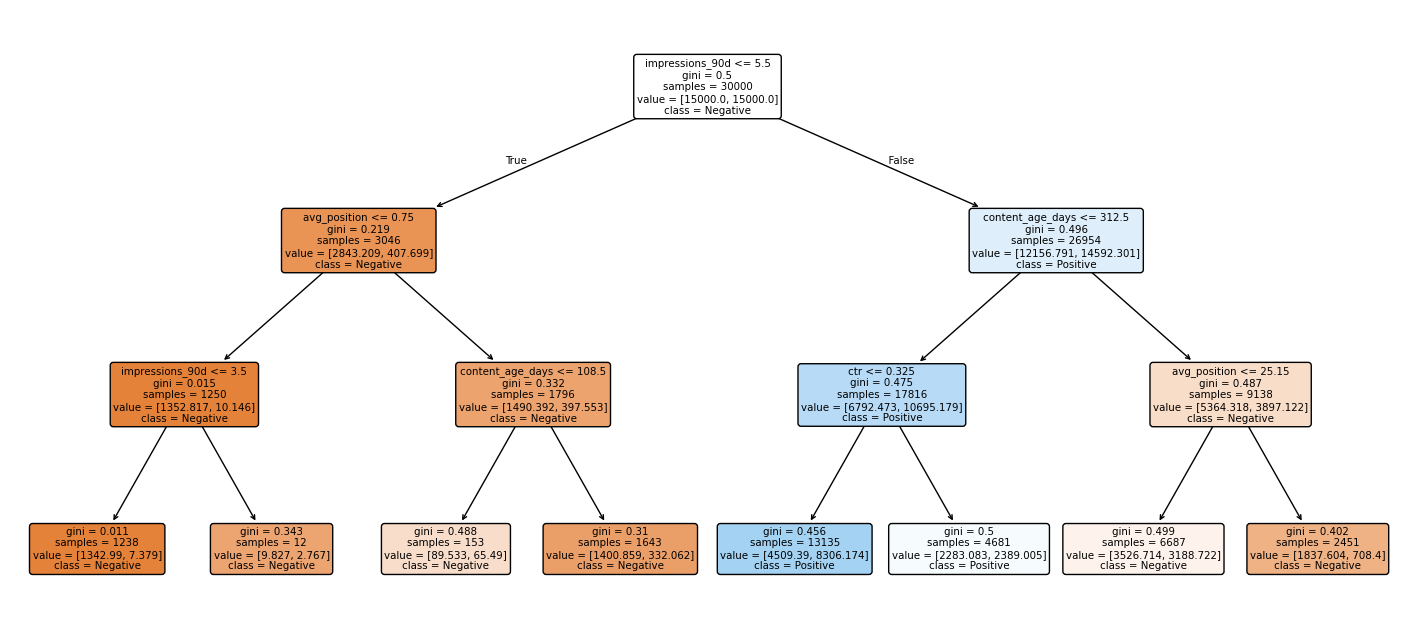

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
tree.fit(X, y)

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X.columns, class_names=["Negative", "Positive"], filled=True, rounded=True)
plt.show()

### Experiment 1: Effect of Tree Depth on Precision@50

I compared Decision Trees with maximum depths of 2, 3, and 4 using in-sample Precision@50.

- **Depth 2:** Precision@50 = `0.6000`
- **Depth 3:** Precision@50 = `0.7200`
- **Depth 4:** Precision@50 = `0.6800`

The results show that `Depth 3` achieved the highest in-sample Precision@50. Increasing the tree depth allows the model to learn more complex patterns, but it can also make the tree harder to interpret and increase the risk of overfitting.

These results measure performance on the same data used for training, so they should not be treated as a reliable estimate of performance on unseen clients.

**Key takeaway:** A deeper tree may improve in-sample performance, but its generalization ability must be evaluated separately.

In [ ]:
features = [c for c in X.columns if c != "impressions_90d"]
features.append("engagement_rate")

X_new = df[features]

tree_new = DecisionTreeClassifier(
    max_depth=3,
    class_weight="balanced",
    random_state=42
)

tree_new.fit(X_new, y)

print("First split:", X_new.columns[tree_new.tree_.feature[0]])

scores_new = tree_new.predict_proba(X_new)[:, 1]
print("Precision@50:", precision_at_k(scores_new, y, 50))

First split: avg_position
Precision@50: 0.74


### Experiment 2: Impact of Feature Selection

I modified the feature set by removing `impressions_90d` and adding `engagement_rate`, while keeping the maximum tree depth at 3.

The first feature selected for the tree's split was **`avg_position`**, and the resulting in-sample Precision@50 was **`0.74`**.

This experiment explores how changing the input features affects the patterns learned by the model. The first split indicates which feature the fitted tree selected for its initial decision, but it does not necessarily mean that feature is the most important for every model or dataset.

**Key takeaway:** Feature selection can change the tree's decision structure and predictive performance. Comparing models on held-out data would help determine whether any improvement generalizes.

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

client_series = df["client_id"].fillna("unknown").astype(str)
unique_clients = client_series.drop_duplicates().to_numpy()

if len(unique_clients) >= 5:
    rng = np.random.default_rng(42)
    shuffled_clients = rng.permutation(unique_clients)
    test_client_count = max(1, int(round(len(shuffled_clients) * 0.2)))
    test_clients = set(shuffled_clients[:test_client_count])

    test_mask = client_series.isin(test_clients).to_numpy()
    train_idx = np.arange(len(df))[~test_mask]
    test_idx = np.arange(len(df))[test_mask]

    if (
        len(train_idx) == 0
        or len(test_idx) == 0
        or len(np.unique(np.asarray(y)[train_idx])) < 2
        or len(np.unique(np.asarray(y)[test_idx])) < 2
    ):
        train_idx, test_idx = train_test_split(
            np.arange(len(df)),
            test_size=0.2,
            random_state=42,
            stratify=y
        )
        split_type = "stratified row split (fallback)"
    else:
        split_type = "client holdout"
else:
    train_idx, test_idx = train_test_split(
        np.arange(len(df)),
        test_size=0.2,
        random_state=42,
        stratify=y
    )
    split_type = "stratified row split (fallback)"

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = np.asarray(y)[train_idx]
y_test = np.asarray(y)[test_idx]

print("Split type:", split_type)
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))

for depth in [2, 3, 4]:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        class_weight="balanced",
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_scores = tree.predict_proba(X_train)[:, 1]
    test_scores = tree.predict_proba(X_test)[:, 1]

    print(f"\nDepth = {depth}")
    print(f"Train Precision@50: {precision_at_k(train_scores, y_train, 50):.4f}")
    print(f"Test Precision@50:  {precision_at_k(test_scores, y_test, 50):.4f}")

Split type: client holdout
Training rows: 27675
Testing rows: 2325

Depth = 2
Train Precision@50: 0.7200
Test Precision@50:  0.5600

Depth = 3
Train Precision@50: 0.7200
Test Precision@50:  0.6000

Depth = 4
Train Precision@50: 0.8600
Test Precision@50:  0.6200


### Experiment 3: Client-Holdout Validation

I evaluated Decision Trees with maximum depths of 2, 3, and 4 using a client-holdout split. The model was trained on 27,675 rows and evaluated on 2,325 rows from held-out clients.

The test Precision@50 increased from **0.56 at depth 2** to **0.60 at depth 3** and **0.62 at depth 4**. Depth 4 achieved the best test result in this experiment, identifying 31 positive examples among its top 50 predictions.

However, its training Precision@50 was 0.86, compared with 0.62 on the test set. This gap suggests possible overfitting or differences between the training and held-out clients. Although the deeper tree performed better on this split, further validation would be needed to establish whether the improvement generalizes.

**Key takeaway:** Evaluating on held-out clients provides a more realistic estimate of generalization to unseen clients than evaluating on training data alone.

### Save your work
**Colab:** *File → Save a copy in GitHub* (your submission) and *File → Save a copy in Drive*.

You now have the two core reflexes of applied ML: **discover before you model**, and **prefer a model you can read and can't fool**. That's the whole foundation the capstone builds on.